# CLIP ViT-B/32 — Phase I: Black-Box Behavioral Analysis

Participant: k{}, k{}  
**Pair:** Human-only group  
**Model:** `openai/clip-vit-base-patch32`  
**Dataset:** Waterbirds (Group DRO)

This notebook documents the Phase I investigation of zero-shot bird classification, subgroup behavior across different backgrounds, and responses to text overlays. The analysis uses model inputs and outputs without examining internal representations.


## 1. Prepare the Environment

This section documents the Python environment, required libraries, GPU availability, and package versions used for the experiments.


In [8]:
import matplotlib.pyplot as plt
import numpy as np

from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel

import torch
print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = "cuda" 
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))
else:
    device = "cpu"
    print("GPU: Not available")

PyTorch: 2.14.1+cu130
CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
Compute capability: (12, 0)


## 2. Load CLIP ViT-B/32

This section loads the pretrained CLIP ViT-B/32 model and its processor and verifies image–text similarity outputs with sample inputs.


In [9]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
model = model.to(device)
model.eval()

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 16607.80it/s]


## 3. Prepare the Waterbirds Dataset

This section loads Waterbirds images, bird labels, background labels, and official dataset splits. It also records the label mappings and number of images in each subgroup.


['image', 'label', 'place', 'bird']
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['landbird', 'waterbird']), 'place': ClassLabel(names=['land', 'water']), 'bird': ClassLabel(names=['Black_footed_Albatross', 'Laysan_Albatross', 'Sooty_Albatross', 'Groove_billed_Ani', 'Crested_Auklet', 'Least_Auklet', 'Parakeet_Auklet', 'Rhinoceros_Auklet', 'Brewer_Blackbird', 'Red_winged_Blackbird', 'Rusty_Blackbird', 'Yellow_headed_Blackbird', 'Bobolink', 'Indigo_Bunting', 'Lazuli_Bunting', 'Painted_Bunting', 'Cardinal', 'Spotted_Catbird', 'Gray_Catbird', 'Yellow_breasted_Chat', 'Eastern_Towhee', 'Chuck_will_Widow', 'Brandt_Cormorant', 'Red_faced_Cormorant', 'Pelagic_Cormorant', 'Bronzed_Cowbird', 'Shiny_Cowbird', 'Brown_Creeper', 'American_Crow', 'Fish_Crow', 'Black_billed_Cuckoo', 'Mangrove_Cuckoo', 'Yellow_billed_Cuckoo', 'Gray_crowned_Rosy_Finch', 'Purple_Finch', 'Northern_Flicker', 'Acadian_Flycatcher', 'Great_Crested_Flycatcher', 'Least_Flycatcher', 'Olive_sided_Flycatcher',

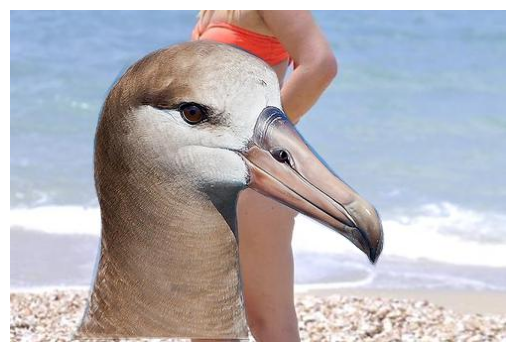

In [10]:
dataset = load_dataset("grodino/waterbirds",split="test",cache_dir="./cache")
print(dataset.column_names)
print(dataset.features)
sample = dataset[0]
image = sample["image"]

plt.imshow(image)
plt.axis("off")
plt.show()

## 4. Run Baseline Classification

This section evaluates zero-shot classification on the Waterbirds test set using fixed waterbird and landbird text descriptions. Predicted labels and similarity scores are stored for analysis.


Actual bird: waterbird
Predicted bird: waterbird
Background: water
landbird: logit=21.7409, probability=0.37%
waterbird: logit=27.3250, probability=99.63%


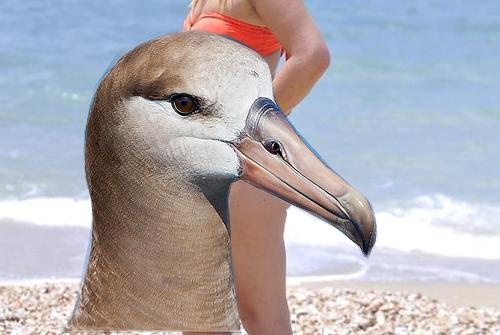

In [11]:
labels = ["landbird", "waterbird"]
texts = ["a photo of a landbird.", "a photo of a waterbird."]

inputs = processor(text=texts, images=image, return_tensors="pt", padding=True).to(device)
with torch.no_grad():
    outputs = model(**inputs)

logits = outputs.logits_per_image
probs = logits.softmax(dim=1)

predicted_index = probs.argmax(dim=1).item()

print("Actual bird:", labels[sample["label"]])
print("Predicted bird:", labels[predicted_index])
print("Background:", "land" if sample["place"] == 0 else "water")

for i, label in enumerate(labels):
    print(
        f"{label}: "
        f"logit={logits[0, i].item():.4f}, "
        f"probability={probs[0, i].item():.2%}"
    )

display(image)

## 5. Calculate Evaluation Metrics

This section calculates classification accuracy, error counts, and the true-class similarity margin, m(x), for each image and subgroup.


In [ ]:
# Write your code here

## 6. Analyze Background Bias

This section compares results across the four bird-type and background-type subgroups, including classification errors and similarity-margin distributions.


In [ ]:
# Write your code here

## 7. Visualize Baseline Results

This section presents subgroup performance charts, similarity-margin distributions, and examples of correct and incorrect predictions.


In [ ]:
# Write your code here

## 8. Generate Typographic Attacks

This section creates edited versions of selected Waterbirds images with correct, misleading, or neutral text overlays under recorded rendering settings.


In [ ]:
# Write your code here

## 9. Evaluate Typographic Attacks

This section compares model outputs for original and text-overlaid images, measuring prediction changes and margin shifts, Δm(x).


In [ ]:
# Write your code here

## 10. Visualize Attack Results

This section presents original-versus-edited image comparisons and visualizations of prediction-flip rates and similarity-margin changes.


In [ ]:
# Write your code here

## 11. Investigate Important Patterns

This section examines selected patterns observed in the subgroup and text-overlay experiments, including their relationships with image and experimental characteristics.


In [ ]:
# Write your code here

## 12. Prepare Midpoint Submission

This section collects the experimental setup, visualizations, observations, limitations, and reproducibility details for the Phase I midpoint submission.


In [ ]:
# Write your code here

## References

- [CLIP ViT-B/32 checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)
- [Official CLIP repository](https://github.com/openai/CLIP)
- [CLIP research paper](https://arxiv.org/abs/2103.00020)
- [Waterbirds / Group DRO repository](https://github.com/kohpangwei/group_DRO)

Waterbirds subgroup comparisons use different images; controlled swaps of the same foreground across backgrounds require an additional image-editing procedure.
